# 532 nm and 1064 nm Spectral Characterization

**Instrument:** HORIBA iHR550 with Synapse Plus detector. The iHR550 has a 550 mm focal length and f/6.4 entrance aperture. Files were acquired at the front entrance by free-space coupling, one accumulation, binning 1, and LabSpec `signal-dark` correction. A filename slit value of 0 µm means the minimum/fully closed setting; it is not interpreted as a calibrated zero-width physical aperture.

A visible mercury lamp was used to calibrate two dominant lines for each grating. This supports useful wavelength work near 532 nm, but four displayed digits are not an uncertainty estimate. At 1064 nm the visible calibration is an extrapolation because no near-IR reference line or calibration residual was recorded.

The nonparametric FWHM is calculated after robust baseline removal. No nominal spectrometer resolution is quadratically subtracted: an intrinsic linewidth requires a measured line-spread function under the same grating, slit, detector, wavelength, and acquisition conditions.

In [1]:
from pathlib import Path
import json, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown


def _locate_project_root(start=None):
    """Find the extracted project folder even if Jupyter was launched one directory above it."""
    start = Path.cwd() if start is None else Path(start)
    candidates = [start, *start.parents]
    for base in candidates:
        if (base / "laser_characterization.py").is_file() and (base / "outputs").is_dir():
            return base.resolve()
        try:
            children = sorted(base.glob("Laser_Characterization_Project*")) + sorted(base.glob("laser_characterization_project*"))
        except OSError:
            children = []
        for child in children:
            if child.is_dir() and (child / "laser_characterization.py").is_file() and (child / "outputs").is_dir():
                return child.resolve()
    raise FileNotFoundError(
        "Could not locate the laser-characterization project folder. Keep the notebooks, "
        "laser_characterization.py, laser_characterization_core.py, and outputs/ together."
    )

PROJECT_ROOT = _locate_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from laser_characterization import *

OUTPUT_DIR = PROJECT_ROOT / "outputs"
FIGURE_DIR = PROJECT_ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)
with (PROJECT_ROOT / "experiment_metadata.json").open() as handle:
    EXPERIMENT = json.load(handle)

# Raw data are optional for viewing the complete precomputed analysis.
# If present, they enable reconstruction of raw-data plots.
try:
    DATA_ROOT = find_data_root(PROJECT_ROOT)
except FileNotFoundError:
    DATA_ROOT = None
    for candidate in [
        PROJECT_ROOT / "data" / "532 and 1064",
        PROJECT_ROOT.parent / "532 and 1064",
        PROJECT_ROOT.parent / "data" / "532 and 1064",
    ]:
        if candidate.is_dir():
            DATA_ROOT = candidate.resolve()
            break
if DATA_ROOT is None:
    warnings.warn(
        "Raw data folder not found. This is OK: all precomputed result tables are included, "
        "and raw-data-only plots will be skipped."
    )


def source_path(stored_path):
    """Resolve a portable path stored relative to the `532 and 1064` data root."""
    p = Path(str(stored_path))
    if p.is_absolute() and p.exists():
        return p
    if DATA_ROOT is None:
        return p
    # Current V4 tables store paths relative to DATA_ROOT.
    q = Path(DATA_ROOT) / p
    if q.exists():
        return q
    # Backward compatibility for older absolute paths.
    parts = p.parts
    if "532 and 1064" in parts:
        i = parts.index("532 and 1064")
        q = Path(DATA_ROOT) / Path(*parts[i+1:])
        if q.exists():
            return q
    return q

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
})
print("Project:", PROJECT_ROOT)
print("Raw data:", DATA_ROOT if DATA_ROOT else "not mounted (using included precomputed results)")


Project: <project root>
Raw data: <project root>\data\532 and 1064


In [2]:
spectral = pd.read_csv(OUTPUT_DIR / "spectral_metrics.csv", parse_dates=["acquired_datetime"])
repeatability = pd.read_csv(OUTPUT_DIR / "spectral_repeatability_sequences.csv")
ps_limits = pd.read_csv(OUTPUT_DIR / "spectral_picosecond_transform_limits.csv")

print(f"Spectra: {len(spectral)}")
print("Conservative high-count warnings:", int(spectral.near_saturation.sum()))

Spectra: 40
Conservative high-count warnings: 4


## 532 nm CW grating comparison

All four 532 nm peaks have fewer than 2.2 samples across the half-maximum width. The measured FWHM values are therefore instrument/sampling-limited upper bounds, not the intrinsic COMPASS linewidth. Center wavelengths near 532 nm are plausible and benefit from visible-region Hg calibration, but a formal absolute uncertainty cannot be reconstructed.

In [3]:
s532 = spectral[spectral.wavelength_family_nm.eq(532)].sort_values(["grating_g_mm", "acquisition_s_filename"])
display(s532[[
    "grating_g_mm", "acquisition_s_filename", "peak_wavelength_nm", "centroid_wavelength_nm",
    "fwhm_nm", "sampling_step_nm", "points_per_fwhm", "width_status",
]].round(6))

,grating_g_mm,acquisition_s_filename,peak_wavelength_nm,centroid_wavelength_nm,fwhm_nm,sampling_step_nm,points_per_fwhm,width_status
1,300,0.5,531.952,531.985766,0.234848,0.149,1.576162,undersampled_and_instrument_response_unremoved
0,300,1.0,531.988,532.097468,0.319945,0.149,2.147280,undersampled_and_instrument_response_unremoved
2,1200,0.5,532.102,532.095846,0.060464,0.034,1.778342,undersampled_and_instrument_response_unremoved
3,1800,0.5,532.228,532.218954,0.036266,0.021,1.726954,undersampled_and_instrument_response_unremoved


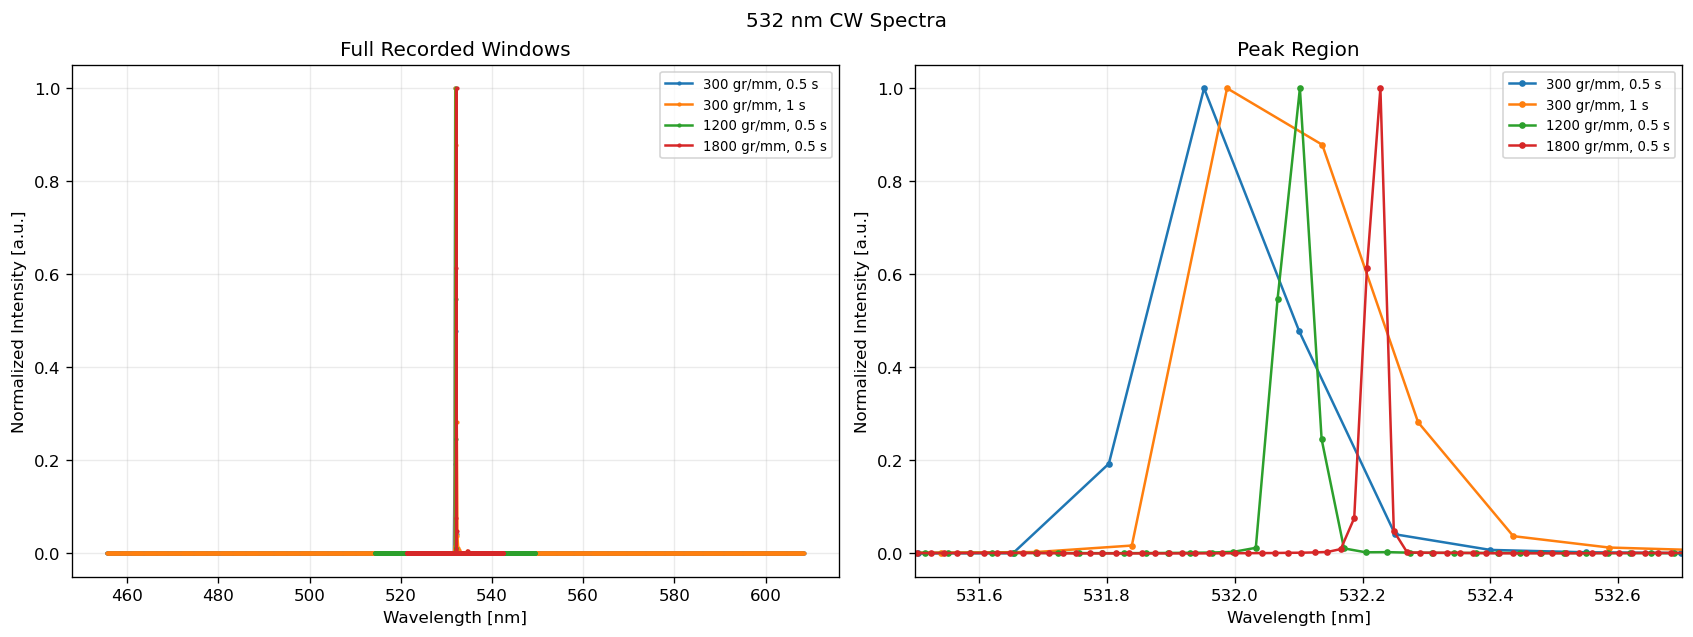

In [4]:
if DATA_ROOT is not None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)
    for _, row in s532.iterrows():
        result, arr = analyze_spectrum(source_path(row["path"]), SpectralConfig(), keep_arrays=True)
        y = arr["corrected_counts"] / max(np.max(arr["corrected_counts"]), 1)
        label = f'{int(row.grating_g_mm)} gr/mm, {row.acquisition_s_filename:g} s'
        axes[0].plot(arr["wavelength_nm"], y, marker=".", markersize=3, label=label)
        axes[1].plot(arr["wavelength_nm"], y, marker="o", markersize=3, label=label)
    axes[0].set_xlabel("Wavelength [nm]")
    axes[0].set_ylabel("Normalized Intensity [a.u.]")
    axes[0].set_title("Full Recorded Windows")
    axes[0].legend(fontsize=8)
    axes[1].set_xlim(531.5, 532.7)
    axes[1].set_xlabel("Wavelength [nm]")
    axes[1].set_ylabel("Normalized Intensity [a.u.]")
    axes[1].set_title("Peak Region")
    axes[1].legend(fontsize=8)
    fig.suptitle("532 nm CW Spectra")
    fig.savefig(FIGURE_DIR / "spectral_532_gratings_v2.png", bbox_inches="tight")
    plt.show()

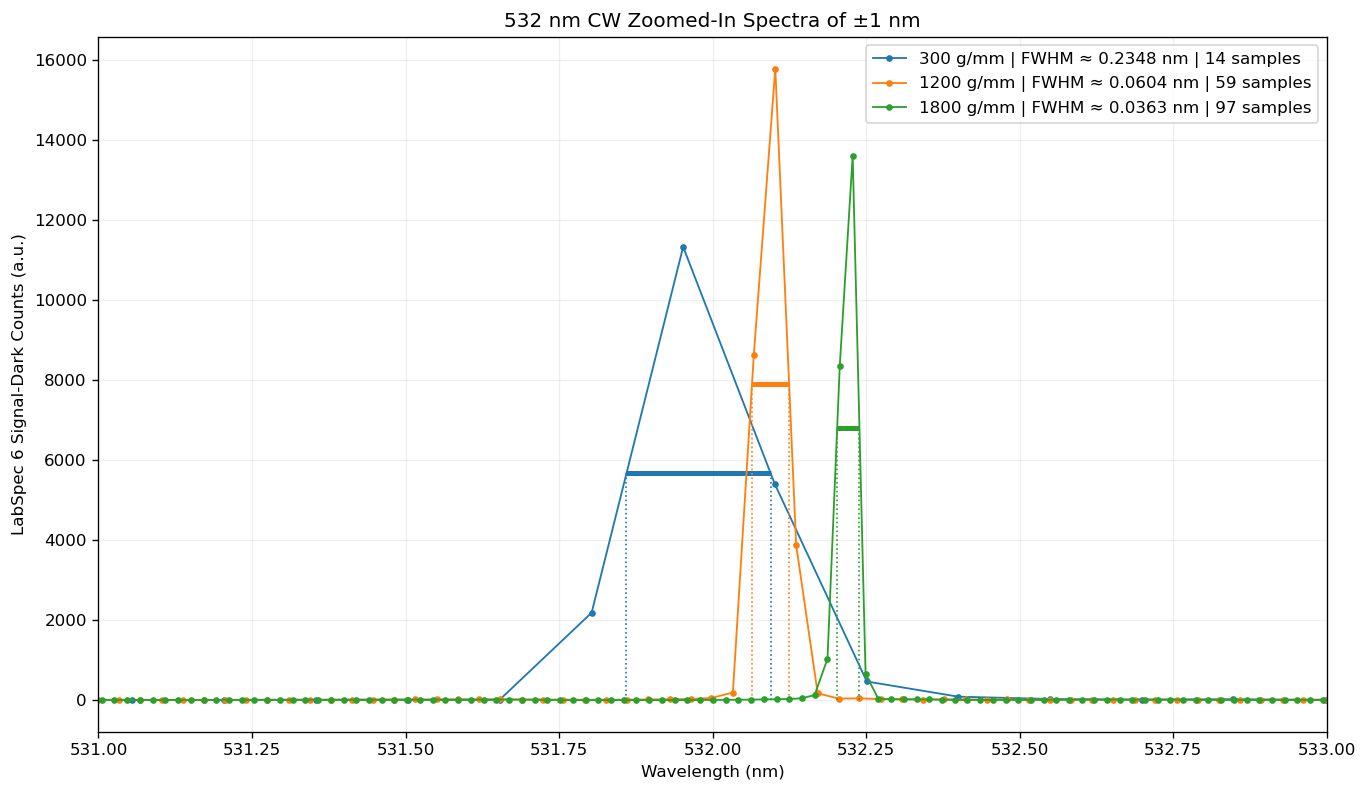

Saved to: <project root>\figures\532nm_raw_non_normalized_527_537_overlay.png

532 nm raw LabSpec sampling:

300 g/mm:
  Samples from 531-533 nm: 14
  Wavelength spacing: 0.1490 nm/point
  Peak wavelength: 531.952 nm
  Interpolated FWHM: 0.23475 nm

1200 g/mm:
  Samples from 531-533 nm: 59
  Wavelength spacing: 0.0340 nm/point
  Peak wavelength: 532.102 nm
  Interpolated FWHM: 0.06043 nm

1800 g/mm:
  Samples from 531-533 nm: 97
  Wavelength spacing: 0.0210 nm/point
  Peak wavelength: 532.228 nm
  Interpolated FWHM: 0.03625 nm



In [21]:
# ============================================================
# 532 nm RAW / NON-NORMALIZED SPECTRAL OVERLAY
# 300, 1200, 1800 g/mm
# 527–537 nm
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ---------- EDIT THESE ----------
PLOT_TITLE = "532 nm CW Zoomed-In Spectra of ±1 nm"
X_LABEL = "Wavelength (nm)"
Y_LABEL = "LabSpec 6 Signal-Dark Counts (a.u.)"

X_MIN = 531
X_MAX = 533

OUTPUT_FILENAME = "532nm_raw_non_normalized_527_537_overlay.png"
FIGSIZE = (11.5, 6.7)
# -------------------------------


# Use matched 0.5 s acquisitions for each grating
s532_raw = spectral[
    (spectral["wavelength_family_nm"] == 532)
    & (spectral["grating_g_mm"].isin([300, 1200, 1800]))
    & (spectral["acquisition_s_filename"] == 0.5)
].copy()

# One matched file per grating
s532_raw = (
    s532_raw
    .sort_values(["grating_g_mm", "path"])
    .groupby("grating_g_mm", as_index=False)
    .first()
)


def calculate_fwhm_raw(wavelength, counts, xmin=527, xmax=537):
    """
    Calculate FWHM from the raw Signal-Dark spectrum.

    No intensity normalization is performed.

    A local baseline is estimated from the outer portions
    of the displayed wavelength window.
    """

    mask = (wavelength >= xmin) & (wavelength <= xmax)

    x = wavelength[mask]
    y = counts[mask]

    # Estimate baseline from both ends of the displayed window
    edge_n = max(5, int(0.20 * len(x)))

    baseline = np.median(
        np.concatenate([
            y[:edge_n],
            y[-edge_n:]
        ])
    )

    # Find maximum
    peak_index = np.argmax(y)
    peak_counts = y[peak_index]
    peak_wavelength = x[peak_index]

    # Half maximum above baseline
    half_max = baseline + 0.5 * (peak_counts - baseline)

    left_crossing = np.nan
    right_crossing = np.nan

    # ---------- LEFT FWHM CROSSING ----------
    for i in range(peak_index - 1, -1, -1):

        if (y[i] - half_max) * (y[i + 1] - half_max) <= 0:

            x1 = x[i]
            x2 = x[i + 1]

            y1 = y[i]
            y2 = y[i + 1]

            if y2 != y1:
                left_crossing = (
                    x1
                    + (half_max - y1)
                    * (x2 - x1)
                    / (y2 - y1)
                )

            break

    # ---------- RIGHT FWHM CROSSING ----------
    for i in range(peak_index, len(x) - 1):

        if (y[i] - half_max) * (y[i + 1] - half_max) <= 0:

            x1 = x[i]
            x2 = x[i + 1]

            y1 = y[i]
            y2 = y[i + 1]

            if y2 != y1:
                right_crossing = (
                    x1
                    + (half_max - y1)
                    * (x2 - x1)
                    / (y2 - y1)
                )

            break

    if np.isfinite(left_crossing) and np.isfinite(right_crossing):
        fwhm = right_crossing - left_crossing
    else:
        fwhm = np.nan

    return {
        "baseline": baseline,
        "half_max": half_max,
        "peak_wavelength": peak_wavelength,
        "peak_counts": peak_counts,
        "left": left_crossing,
        "right": right_crossing,
        "fwhm": fwhm,
        "points_in_window": len(x),
    }


# ============================================================
# Plot
# ============================================================

fig, ax = plt.subplots(figsize=FIGSIZE)

results = []

for _, row in s532_raw.iterrows():

    grating = int(row["grating_g_mm"])

    result, arr = analyze_spectrum(
        source_path(row["path"]),
        SpectralConfig(),
        keep_arrays=True
    )

    wavelength = np.asarray(
        arr["wavelength_nm"],
        dtype=float
    )

    # IMPORTANT:
    # This is baseline/dark-corrected detector signal,
    # NOT normalized intensity.
    counts = np.asarray(
        arr["corrected_counts"],
        dtype=float
    )

    mask = (
        (wavelength >= X_MIN)
        & (wavelength <= X_MAX)
    )

    wl_plot = wavelength[mask]
    counts_plot = counts[mask]

    # Calculate FWHM directly from non-normalized data
    fwhm_result = calculate_fwhm_raw(
        wavelength,
        counts,
        xmin=X_MIN,
        xmax=X_MAX
    )

    # Actual measured samples
    line, = ax.plot(
        wl_plot,
        counts_plot,
        marker="o",
        markersize=3,
        linewidth=1.1,
        label=(
            f"{grating} g/mm"
            f" | FWHM ≈ {fwhm_result['fwhm']:.4f} nm"
            f" | {fwhm_result['points_in_window']} samples"
        )
    )

    # Draw FWHM horizontal segment
    if (
        np.isfinite(fwhm_result["left"])
        and np.isfinite(fwhm_result["right"])
    ):

        ax.hlines(
            y=fwhm_result["half_max"],
            xmin=fwhm_result["left"],
            xmax=fwhm_result["right"],
            linewidth=3,
            color=line.get_color()
        )

        # Optional vertical FWHM crossing lines
        ax.vlines(
            [
                fwhm_result["left"],
                fwhm_result["right"]
            ],
            ymin=fwhm_result["baseline"],
            ymax=fwhm_result["half_max"],
            linestyles=":",
            linewidth=1,
            color=line.get_color()
        )

    # Save information for printed output
    wavelength_step = np.median(
        np.diff(wavelength)
    )

    results.append({
        "grating": grating,
        "points": fwhm_result["points_in_window"],
        "step": wavelength_step,
        "peak": fwhm_result["peak_wavelength"],
        "fwhm": fwhm_result["fwhm"]
    })


# ============================================================
# Formatting
# ============================================================

ax.set_xlim(X_MIN, X_MAX)

ax.set_xlabel(X_LABEL)
ax.set_ylabel(Y_LABEL)

ax.set_title(PLOT_TITLE)

ax.legend()

ax.grid(alpha=0.20)

fig.tight_layout()


# ============================================================
# Save
# ============================================================

save_path = FIGURE_DIR / OUTPUT_FILENAME

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {save_path}")


# ============================================================
# Print sampling information
# ============================================================

print("\n532 nm raw LabSpec sampling:\n")

for r in sorted(results, key=lambda x: x["grating"]):

    print(
        f"{r['grating']} g/mm:"
    )

    print(
        f"  Samples from {X_MIN}-{X_MAX} nm: "
        f"{r['points']}"
    )

    print(
        f"  Wavelength spacing: "
        f"{r['step']:.4f} nm/point"
    )

    print(
        f"  Peak wavelength: "
        f"{r['peak']:.3f} nm"
    )

    print(
        f"  Interpolated FWHM: "
        f"{r['fwhm']:.5f} nm"
    )

    print()

## 1064 nm CW slit series: direct evidence of instrumental broadening

At 1200 gr/mm, widening the nominal entrance slit from 10 to 200 µm increases the measured FWHM from about 0.0559 to 0.2246 nm. This demonstrates that the measured narrow-line width is strongly configuration dependent.

In [6]:
cw_slit = spectral[
    spectral.wavelength_family_nm.eq(1064)
    & spectral["mode"].eq("cw")
    & spectral.grating_g_mm.eq(1200)
].sort_values("slit_um_filename")
display(cw_slit[[
    "slit_um_filename", "peak_wavelength_nm", "centroid_wavelength_nm", "fwhm_nm",
    "points_per_fwhm", "width_status",
]].round(6))

,slit_um_filename,peak_wavelength_nm,centroid_wavelength_nm,fwhm_nm,points_per_fwhm,width_status
26,10,1060.58,1060.591297,0.055884,1.862799,undersampled_and_instrument_response_unremoved
27,50,1060.58,1060.579830,0.061156,2.038545,undersampled_and_instrument_response_unremoved
28,100,1060.61,1060.600138,0.111227,3.707570,instrument_response_unremoved_not_intrinsic_linewidth
29,200,1060.69,1060.297866,0.224608,7.486938,instrument_response_unremoved_not_intrinsic_linewidth


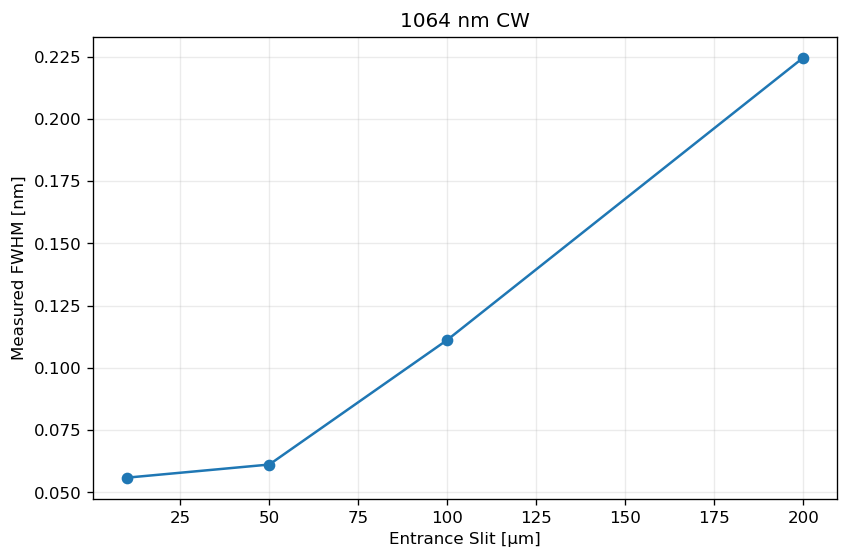

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(cw_slit.slit_um_filename, cw_slit.fwhm_nm, marker="o")
ax.set_xlabel("Entrance Slit [µm]")
ax.set_ylabel("Measured FWHM [nm]")
ax.set_title("1064 nm CW")
fig.savefig(FIGURE_DIR / "spectral_1064_slit_broadening_v2.png", bbox_inches="tight")
plt.show()

## 65 ns spectra: acquisition-state and high-count warning

The 300 gr/mm, 10 µm series separates into an early lower-count sequence with FWHM around 0.52–0.58 nm and a later high-count sequence with FWHM around 2.28–2.38 nm. Four later files exceed the project's conservative 85% full-scale quality-control threshold. This threshold is not a manufacturer linearity specification; it is a warning that linearity was not established close to the exported full scale. These sequences must not be averaged together as ordinary repeats.

In [8]:
s65 = spectral[
    spectral.wavelength_family_nm.eq(1064)
    & spectral["mode"].eq("65_ns")
    & spectral.grating_g_mm.eq(300)
    & spectral.slit_um_filename.eq(10)
].sort_values("acquired_datetime")
display(s65[[
    "acquired_datetime", "file", "peak_raw_counts", "detector_full_scale_fraction",
    "peak_wavelength_nm", "fwhm_nm", "near_saturation", "sequence_id", "width_status",
]].round(6))

,acquired_datetime,file,peak_raw_counts,detector_full_scale_fraction,peak_wavelength_nm,fwhm_nm,near_saturation,sequence_id,width_status
4,2026-08-25 13:30:38,Laser_1064nm_Mode_65nanoseconds_Acq_0_5s_Slit_10um_Grad_300.txt,3680.0,0.056153,1059.89,0.580253,False,seq1,instrument_response_unremoved_not_intrinsic_linewidth
5,2026-08-25 13:30:56,Laser_1064nm_Mode_65nanoseconds_Acq_0_5s_Slit_10um_Grad_300_(1).txt,3836.0,0.058534,1059.89,0.573295,False,seq1,instrument_response_unremoved_not_intrinsic_linewidth
6,2026-08-25 13:31:07,Laser_1064nm_Mode_65nanoseconds_Acq_0_5s_Slit_10um_Grad_300_(2).txt,4084.0,0.062318,1059.89,0.555491,False,seq1,instrument_response_unremoved_not_intrinsic_linewidth
7,2026-08-25 13:31:19,Laser_1064nm_Mode_65nanoseconds_Acq_0_5s_Slit_10um_Grad_300_(3).txt,4256.0,0.064942,1059.89,0.516641,False,seq1,instrument_response_unremoved_not_intrinsic_linewidth
8,2026-08-25 13:35:34,Laser_1064nm_Mode_65nanoseconds_Acq_0_5s_Slit_10um_Grad_300 (2).txt,57246.7,0.873529,1059.16,2.376034,True,seq2,not_reportable_high_count_linearity_not_established
9,2026-08-25 13:36:36,Laser_1064nm_Mode_65nanoseconds_Acq_0_5s_Slit_10um_Grad_300_(6).txt,59830.2,0.912950,1059.16,2.322689,True,seq2,not_reportable_high_count_linearity_not_established
10,2026-08-25 13:36:55,Laser_1064nm_Mode_65nanoseconds_Acq_0_5s_Slit_10um_Grad_300_(4).txt,59485.6,0.907692,1059.30,2.286831,True,seq2,not_reportable_high_count_linearity_not_established
11,2026-08-25 13:37:07,Laser_1064nm_Mode_65nanoseconds_Acq_0_5s_Slit_10um_Grad_300_(5).txt,59607.4,0.909551,1059.30,2.280212,True,seq2,not_reportable_high_count_linearity_not_established


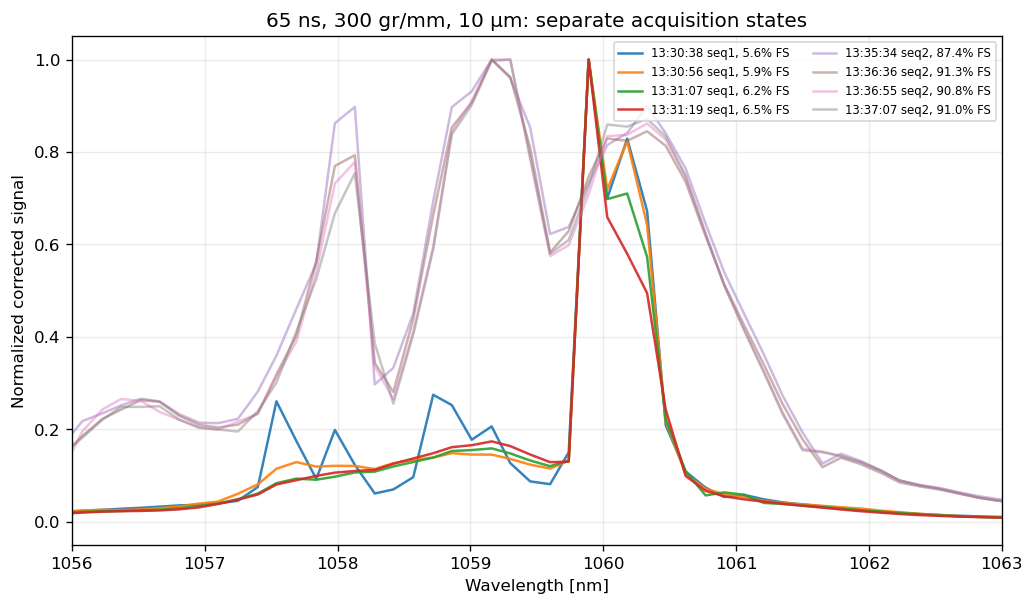

In [9]:
if DATA_ROOT is not None:
    fig, ax = plt.subplots(figsize=(10, 5.5))
    for _, row in s65.iterrows():
        result, arr = analyze_spectrum(source_path(row["path"]), SpectralConfig(), keep_arrays=True)
        y = arr["corrected_counts"] / max(np.max(arr["corrected_counts"]), 1)
        alpha = 0.45 if row.near_saturation else 0.9
        ax.plot(arr["wavelength_nm"], y, alpha=alpha,
                label=f'{row.acquired_datetime.time()} {row.sequence_id}, {row.detector_full_scale_fraction:.1%} FS')
    ax.set_xlim(1056, 1063)
    ax.set_xlabel("Wavelength [nm]")
    ax.set_ylabel("Normalized corrected signal")
    ax.set_title("65 ns, 300 gr/mm, 10 µm: separate acquisition states")
    ax.legend(fontsize=7, ncol=2)
    fig.savefig(FIGURE_DIR / "spectral_65ns_sequences_v2.png", bbox_inches="tight")
    plt.show()

## 1064 nm operating-mode comparison

The narrow CW/65 ns peaks lie near 1059–1061 nm. That is within the GSL106A manufacturer band of 1064 ± 10 nm and is therefore physically plausible. It does not prove that the absolute calibration at 1064 nm is correct. The broadband picosecond-mode spectra peak/centroid nearer 1053–1055 nm; the 1200 gr/mm peak near 1052.89 nm lies just below the nominal lower limit, but the visible-only wavelength calibration and uncorrected system spectral response prevent a definitive source-wavelength conclusion.

In [10]:
representative = pd.concat([
    spectral[(spectral["mode"].eq("cw")) & spectral.grating_g_mm.eq(1200) & spectral.slit_um_filename.eq(10)].head(1),
    spectral[(spectral["mode"].eq("65_ns")) & spectral.grating_g_mm.eq(1200) & spectral.slit_um_filename.eq(10)].head(1),
    spectral[(spectral["mode"].eq("picosecond")) & spectral.grating_g_mm.eq(1200) & spectral.slit_um_filename.eq(10)].head(1),
])
display(representative[[
    "mode", "peak_wavelength_nm", "centroid_wavelength_nm", "fwhm_nm",
    "points_per_fwhm", "peak_within_gsl_1064_plusminus10_nm",
    "centroid_within_gsl_1064_plusminus10_nm", "absolute_center_claim_status",
]].round(6))

,mode,peak_wavelength_nm,centroid_wavelength_nm,fwhm_nm,points_per_fwhm,peak_within_gsl_1064_plusminus10_nm,centroid_within_gsl_1064_plusminus10_nm,absolute_center_claim_status
26,cw,1060.58,1060.591297,0.055884,1.862799,True,True,absolute wavelength is unvalidated at 1064 nm; relative shifts within a fixed setting are more credible
18,65_ns,1059.49,1059.887161,0.048671,1.622383,True,True,absolute wavelength is unvalidated at 1064 nm; relative shifts within a fixed setting are more credible
38,picosecond,1052.89,1053.001934,8.492075,283.069176,False,False,absolute wavelength is unvalidated at 1064 nm; relative shifts within a fixed setting are more credible


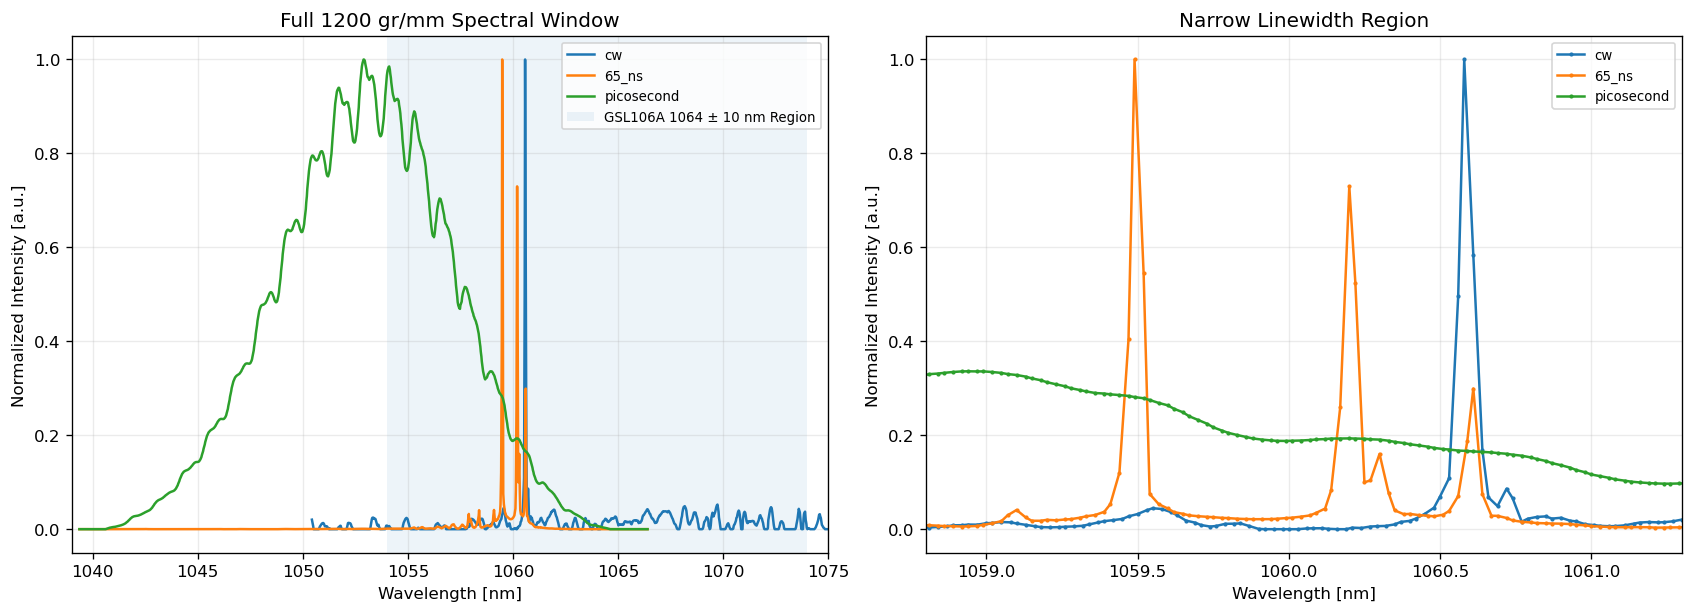

In [11]:
if DATA_ROOT is not None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
    for _, row in representative.iterrows():
        result, arr = analyze_spectrum(source_path(row["path"]), SpectralConfig(), keep_arrays=True)
        y = arr["corrected_counts"] / max(np.max(arr["corrected_counts"]), 1)
        axes[0].plot(arr["wavelength_nm"], y, label=row["mode"])
        axes[1].plot(arr["wavelength_nm"], y, marker=".", markersize=3, label=row["mode"])
    axes[0].axvspan(1054, 1074, alpha=0.08, label="GSL106A 1064 ± 10 nm Region")
    axes[0].set_xlim(1039, 1075)
    axes[0].set_xlabel("Wavelength [nm]")
    axes[0].set_ylabel("Normalized Intensity [a.u.]")
    axes[0].set_title("Full 1200 gr/mm Spectral Window")
    axes[1].set_xlim(1058.8, 1061.3)
    axes[1].set_xlabel("Wavelength [nm]")
    axes[1].set_ylabel("Normalized Intensity [a.u.]")
    axes[1].set_title("Narrow Linewidth Region")
    axes[0].legend(fontsize=8)
    axes[1].legend(fontsize=8)
    fig.savefig(FIGURE_DIR / "spectral_1064_modes_v2.png", bbox_inches="tight")
    plt.show()

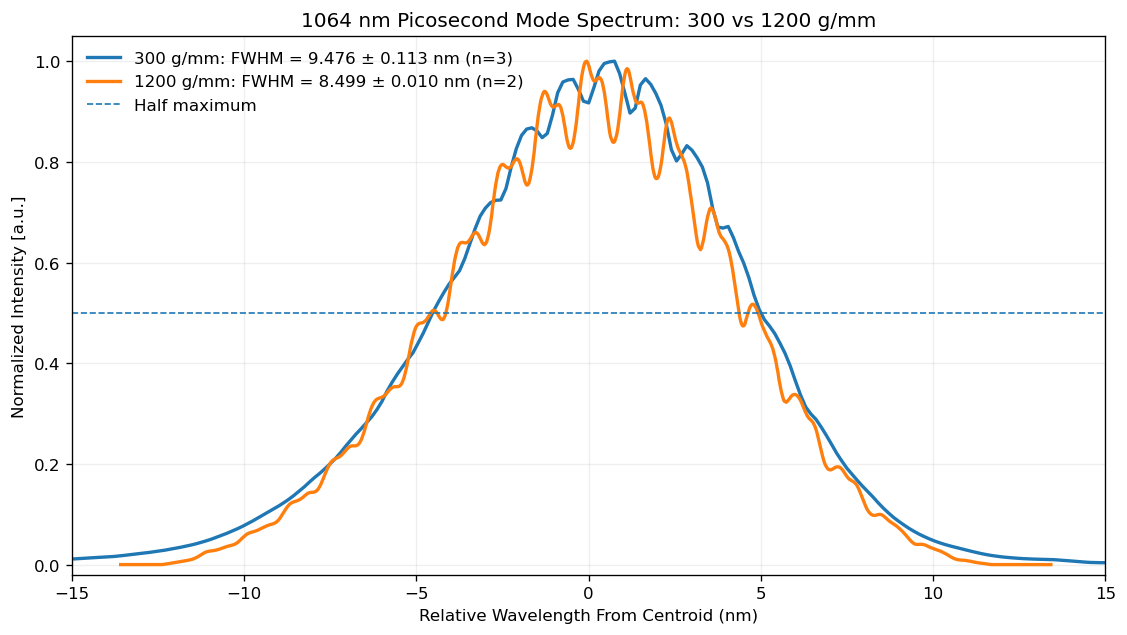

Saved to: <project root>\figures\1064_picosecond_300_vs_1200.png

300 g/mm:
  FWHM = 9.476455 ± 0.112512 nm
  n = 3

1200 g/mm:
  FWHM = 8.499118 ± 0.009960 nm
  n = 2


In [12]:
# ============================================================
# 1064 nm Picosecond Spectrum: 300 vs 1200 g/mm
# Matched conditions: 10 µm slit, 0.5 s acquisition
# ============================================================

# ---------- EDIT THESE FOR YOUR SLIDE ----------
PLOT_TITLE = "1064 nm Picosecond Mode Spectrum: 300 vs 1200 g/mm"
X_LABEL = "Relative Wavelength From Centroid (nm)"
Y_LABEL = "Normalized Intensity [a.u.]"

LABEL_300 = "300 g/mm"
LABEL_1200 = "1200 g/mm"

X_LIMITS = (-15, 15)
FIGSIZE = (9.5, 5.4)
OUTPUT_FILENAME = "1064_picosecond_300_vs_1200.png"
# ------------------------------------------------


# Select matched picosecond measurements
ps_compare = spectral[
    (spectral["mode"] == "picosecond")
    & (spectral["grating_g_mm"].isin([300, 1200]))
    & (spectral["slit_um_filename"] == 10)
    & (spectral["acquisition_s_filename"] == 0.5)
].copy()

# For the 300 g/mm data, use sequence 1 so that the
# separate later acquisition state is not mixed into the mean.
ps_300 = ps_compare[
    (ps_compare["grating_g_mm"] == 300)
    & (ps_compare["sequence_id"] == "seq1")
].copy()

ps_1200 = ps_compare[
    ps_compare["grating_g_mm"] == 1200
].copy()


def build_mean_spectrum(rows):
    """
    Baseline-correct each raw spectrum using the same analysis
    routine as the rest of the notebook, normalize each spectrum,
    center it on its centroid wavelength, then average the repeats.
    """

    traces = []
    fwhm_values = []

    for _, row in rows.iterrows():

        result, arr = analyze_spectrum(
            source_path(row["path"]),
            SpectralConfig(),
            keep_arrays=True
        )

        wavelength = np.asarray(arr["wavelength_nm"], dtype=float)
        signal = np.asarray(arr["corrected_counts"], dtype=float)

        # Prevent negative baseline-corrected values from affecting normalization
        signal = np.clip(signal, 0, None)

        # Normalize each acquisition independently
        signal = signal / np.nanmax(signal)

        # Center each spectrum at its measured centroid
        centroid = float(result["centroid_wavelength_nm"])
        wavelength_relative = wavelength - centroid

        traces.append((wavelength_relative, signal))
        fwhm_values.append(float(result["fwhm_nm"]))

    # Find wavelength range common to every repeat
    x_min = max(np.min(x) for x, _ in traces)
    x_max = min(np.max(x) for x, _ in traces)

    # Use the finest available wavelength step
    dx = min(np.median(np.diff(x)) for x, _ in traces)

    common_x = np.arange(x_min, x_max + dx / 2, dx)

    # Interpolate all repeats onto common wavelength grid
    stack = np.vstack([
        np.interp(common_x, x, y)
        for x, y in traces
    ])

    mean_signal = np.mean(stack, axis=0)
    mean_signal /= np.max(mean_signal)

    fwhm_values = np.asarray(fwhm_values)

    return {
        "x": common_x,
        "y": mean_signal,
        "fwhm_mean": np.mean(fwhm_values),
        "fwhm_sd": (
            np.std(fwhm_values, ddof=1)
            if len(fwhm_values) > 1
            else np.nan
        ),
        "n": len(fwhm_values),
    }


# Reconstruct both grating conditions
spec_300 = build_mean_spectrum(ps_300)
spec_1200 = build_mean_spectrum(ps_1200)


# Make legend labels with measured FWHM statistics
label_300 = (
    f"{LABEL_300}: "
    f"FWHM = {spec_300['fwhm_mean']:.3f} ± "
    f"{spec_300['fwhm_sd']:.3f} nm "
    f"(n={spec_300['n']})"
)

label_1200 = (
    f"{LABEL_1200}: "
    f"FWHM = {spec_1200['fwhm_mean']:.3f} ± "
    f"{spec_1200['fwhm_sd']:.3f} nm "
    f"(n={spec_1200['n']})"
)


# ---------------- PLOT ----------------
fig, ax = plt.subplots(figsize=FIGSIZE)

ax.plot(
    spec_300["x"],
    spec_300["y"],
    linewidth=2,
    label=label_300
)

ax.plot(
    spec_1200["x"],
    spec_1200["y"],
    linewidth=2,
    label=label_1200
)

# Half-maximum reference
ax.axhline(
    0.5,
    linestyle="--",
    linewidth=1,
    label="Half maximum"
)

ax.set_xlim(*X_LIMITS)
ax.set_ylim(-0.02, 1.05)

ax.set_xlabel(X_LABEL)
ax.set_ylabel(Y_LABEL)
ax.set_title(PLOT_TITLE)

ax.legend(frameon=False)
ax.grid(alpha=0.20)

fig.tight_layout()

# Save directly into project figures folder
save_path = FIGURE_DIR / OUTPUT_FILENAME
fig.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

print(f"Saved to: {save_path}")

print()
print("300 g/mm:")
print(
    f"  FWHM = {spec_300['fwhm_mean']:.6f} "
    f"± {spec_300['fwhm_sd']:.6f} nm"
)
print(f"  n = {spec_300['n']}")

print()
print("1200 g/mm:")
print(
    f"  FWHM = {spec_1200['fwhm_mean']:.6f} "
    f"± {spec_1200['fwhm_sd']:.6f} nm"
)
print(f"  n = {spec_1200['n']}")

## Repeatability is not accuracy

Files are grouped only when their physical settings match and they are time-contiguous. High-count warning files are excluded from the repeatability summary. A standard deviation within a sequence describes acquisition repeatability; it does not include wavelength-calibration error, slit-position error, instrument drift outside the sequence, or spectral-response correction.

In [13]:
display(repeatability[repeatability.n.gt(1)].round(6))

,wavelength_family_nm,mode,grating_g_mm,slit_um_filename,acquisition_s_filename,sequence_id,n,acquired_first,acquired_last,peak_wavelength_mean_nm,peak_wavelength_std_nm,centroid_wavelength_mean_nm,fwhm_mean_nm,fwhm_std_nm,peak_counts_cv_percent,repeatability_scope
4,1064,65_ns,300,10,0.5,seq1,4,2026-08-25 13:30:38,2026-08-25 13:31:19,1059.890000,0.000000,1059.461432,0.556420,0.028496,6.465915,within this contiguous acquisition sequence only; excludes wavelength calibration uncertainty
5,1064,65_ns,300,50,0.5,seq1,2,2026-08-25 13:31:42,2026-08-25 13:31:57,1060.180000,0.000000,1059.752804,0.666879,0.002055,2.087396,within this contiguous acquisition sequence only; excludes wavelength calibration uncertainty
6,1064,65_ns,300,50,1.0,seq1,2,2026-08-25 13:32:19,2026-08-25 13:32:36,1060.180000,0.000000,1059.748894,0.617603,0.014153,1.938494,within this contiguous acquisition sequence only; excludes wavelength calibration uncertainty
7,1064,65_ns,300,100,1.0,seq1,2,2026-08-25 13:32:54,2026-08-25 13:33:07,1060.330000,0.000000,1059.899820,0.341990,0.007956,0.285405,within this contiguous acquisition sequence only; excludes wavelength calibration uncertainty
9,1064,65_ns,1200,10,0.5,seq1,2,2026-08-25 13:17:33,2026-08-25 13:17:59,1059.490000,0.000000,1059.937399,0.050121,0.001833,2.364710,within this contiguous acquisition sequence only; excludes wavelength calibration uncertainty
11,1064,cw,300,10,0.5,seq1,4,2026-08-25 10:19:24,2026-08-25 10:21:13,1060.487500,0.585000,1060.540455,0.308885,0.015439,24.556731,within this contiguous acquisition sequence only; excludes wavelength calibration uncertainty
16,1064,picosecond,300,10,0.5,seq1,3,2026-08-25 13:38:54,2026-08-25 13:40:39,1054.026667,0.145029,1053.408304,9.476455,0.112512,74.683128,within this contiguous acquisition sequence only; excludes wavelength calibration uncertainty
17,1064,picosecond,300,10,0.5,seq2,3,2026-08-25 13:43:05,2026-08-25 13:43:37,1054.466667,0.638931,1053.628635,9.302170,0.143702,1.415908,within this contiguous acquisition sequence only; excludes wavelength calibration uncertainty
20,1064,picosecond,1200,10,0.5,seq1,2,2026-08-25 13:11:46,2026-08-25 13:12:25,1052.890000,0.000000,1052.972293,8.499118,0.009960,0.274441,within this contiguous acquisition sequence only; excludes wavelength calibration uncertainty


## Picosecond-mode spectral bandwidth and transform limits

The picosecond-mode FWHM is well sampled: approximately 8.49–9.61 nm, depending on grating and acquisition. For an optical frequency FWHM \(\Delta\nu\), ideal transform-limited intensity durations are

\[
\Delta t_\mathrm{TL}=\frac{0.441}{\Delta\nu}\quad\text{(Gaussian)},\qquad
\Delta t_\mathrm{TL}=\frac{0.315}{\Delta\nu}\quad\text{(sech}^2\text{)}.
\]

These values are lower bounds. The actual pulse can be longer because of chirp or arbitrary spectral phase, and the spectral response of the spectrometer/detector was not corrected.

In [14]:
display(ps_limits[[
    "grating_g_mm", "slit_um_filename", "peak_wavelength_nm", "centroid_wavelength_nm",
    "fwhm_nm", "fwhm_frequency_ghz", "points_per_fwhm",
    "transform_limit_gaussian_ps", "transform_limit_sech2_ps",
]].round(6))

print(
    f'Gaussian transform-limit range: {ps_limits.transform_limit_gaussian_ps.min():.3f}–'
    f'{ps_limits.transform_limit_gaussian_ps.max():.3f} ps.'
)

,grating_g_mm,slit_um_filename,peak_wavelength_nm,centroid_wavelength_nm,fwhm_nm,fwhm_frequency_ghz,points_per_fwhm,transform_limit_gaussian_ps,transform_limit_sech2_ps
0,300,10,1054.17,1053.376888,9.606157,2591.487302,64.041048,0.170173,0.121552
1,300,10,1053.88,1053.417272,9.405114,2538.647798,62.700762,0.173715,0.124082
2,300,10,1054.03,1053.430751,9.418095,2541.427994,62.787298,0.173524,0.123946
3,300,10,1055.20,1053.625521,9.443421,2542.614353,62.956141,0.173444,0.123888
4,300,10,1054.17,1053.588225,9.306951,2510.769474,62.046342,0.175643,0.125460
5,300,10,1054.03,1053.672159,9.156137,2470.739872,61.040911,0.178489,0.127492
6,300,50,1054.03,1053.574659,9.603419,2591.436792,64.022791,0.170176,0.121554
7,300,50,1054.03,1053.591685,9.557284,2578.987704,63.715230,0.170997,0.122141
8,1200,10,1052.89,1053.001934,8.492075,2296.511037,283.069176,0.192030,0.137165
9,1200,10,1052.89,1052.942652,8.506160,2300.320085,283.538682,0.191712,0.136937


Gaussian transform-limit range: 0.170–0.192 ps.


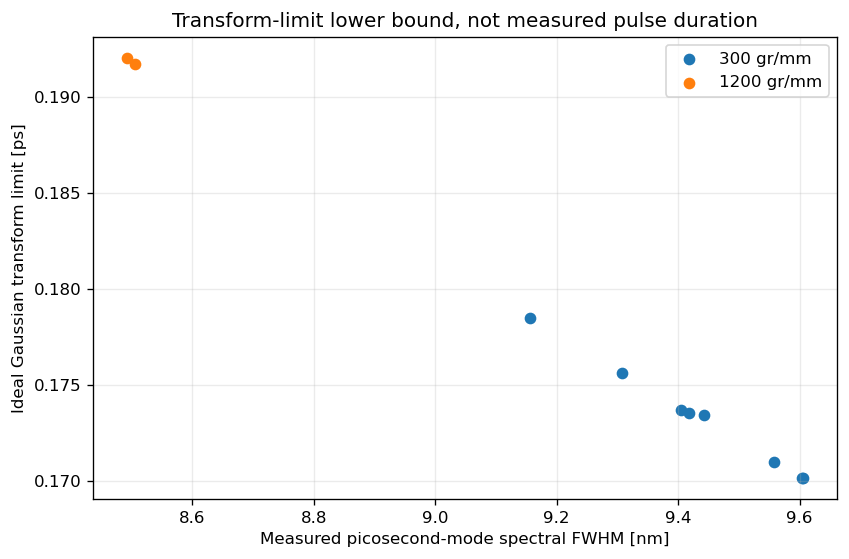

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
for grating, d in ps_limits.groupby("grating_g_mm"):
    ax.scatter(d.fwhm_nm, d.transform_limit_gaussian_ps, label=f"{int(grating)} gr/mm")
ax.set_xlabel("Measured picosecond-mode spectral FWHM [nm]")
ax.set_ylabel("Ideal Gaussian transform limit [ps]")
ax.set_title("Transform-limit lower bound, not measured pulse duration")
ax.legend()
fig.savefig(FIGURE_DIR / "spectral_transform_limits_v2.png", bbox_inches="tight")
plt.show()

## Spectral confidence verdict

| Quantity | Verdict | Interpretation |
|---|---|---|
| 532 nm center wavelength | **Supported with calibration caveat** | Visible Hg calibration is regionally relevant, but residuals/absolute uncertainty were not saved. |
| 532 nm intrinsic linewidth | **Not supported** | All measured peaks have fewer than 2.2 samples across FWHM and instrument response is not removed. |
| 1064 CW/65 ns center near 1059–1061 nm | **Physically plausible, absolute value unvalidated** | It lies within 1064 ± 10 nm, but visible Hg calibration was extrapolated to the near-IR. |
| 1064 narrow intrinsic linewidth | **Not supported** | Slit dependence and undersampling/instrument response dominate. |
| 65 ns high-count broad spectra | **Not reportable as ordinary repeats** | Distinct acquisition state and ≥85% full-scale QC warning. |
| Picosecond-mode bandwidth | **Supported with caveat** | 8.49–9.61 nm and well sampled; system spectral response is uncorrected. |
| Transform-limited duration | **Supported as a lower bound only** | Gaussian 0.170–0.192 ps; actual pulse needs phase-sensitive or autocorrelation/FROG measurement. |